In [ ]:
# Install current Diffusers from its source, as required by the official FLUX.2 Klein card.
# %pip install -q --upgrade git+https://github.com/huggingface/diffusers.git transformers accelerate sentencepiece protobuf

In [ ]:
!pip install diffusers transformers accelerate torchao sentencepiece protobuf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 114.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 147.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 125.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 35.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [ ]:
!pip install diffusers

  Using cached diffusers-0.41.0-py3-none-any.whl.metadata (20 kB)
Using cached diffusers-0.41.0-py3-none-any.whl (6.1 MB)


In [8]:
import os, gc, json, time, platform, subprocess, sys
from datetime import datetime
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from diffusers import Flux2KleinPipeline

In [9]:
SEED = 42
IMAGE_SIZE = 512
FLUX2_STEPS = 4
KONTEXT_STEPS = 8
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if DEVICE != "cuda":
    raise RuntimeError("CUDA GPU not detected. In Colab select Runtime > Change runtime type > T4 GPU.")

props = torch.cuda.get_device_properties(0)
free_bytes, total_bytes = torch.cuda.mem_get_info(0)

print("GPU:", torch.cuda.get_device_name(0))
print(f"Total VRAM: {props.total_memory / 1024**3:.2f} GiB")
print(f"Currently free VRAM: {free_bytes / 1024**3:.2f} GiB")
print("Compute capability:", torch.cuda.get_device_capability(0))

GPU: NVIDIA A100-SXM4-80GB
Total VRAM: 79.25 GiB
Currently free VRAM: 78.83 GiB
Compute capability: (8, 0)


In [10]:
def make_retail_fixture(size=512):

    img = Image.new("RGB", (size, size), (235, 224, 207))

    d = ImageDraw.Draw(img)
    # subtle tabletop / backdrop boundary
    d.rectangle((0, int(size*0.72), size, size), fill=(218, 203, 184))

    # soft shadow
    d.ellipse((125, 365, 390, 425), fill=(190, 176, 159))

    # glass serum bottle
    d.rounded_rectangle((174, 130, 338, 390), radius=28, fill=(240, 239, 231), outline=(181, 177, 166), width=4)
    d.rounded_rectangle((218, 85, 294, 145), radius=9, fill=(82, 79, 74))
    d.rectangle((224, 72, 288, 92), fill=(55, 53, 50))

    # label
    d.rounded_rectangle((190, 220, 322, 315), radius=8, fill=(246, 242, 229), outline=(202, 196, 180), width=2)

    try:
        font = ImageFont.truetype("DejaVuSans.ttf", 16)
        small = ImageFont.truetype("DejaVuSans.ttf", 11)
    except OSError:
        font = small = ImageFont.load_default()

    d.text((207, 242), "BOTANICAL", fill=(64, 64, 59), font=font)
    d.text((220, 269), "SERUM 30 ml", fill=(90, 86, 78), font=small)

    # highlight line
    d.line((192, 155, 192, 205), fill=(255, 255, 249), width=5)

    return img

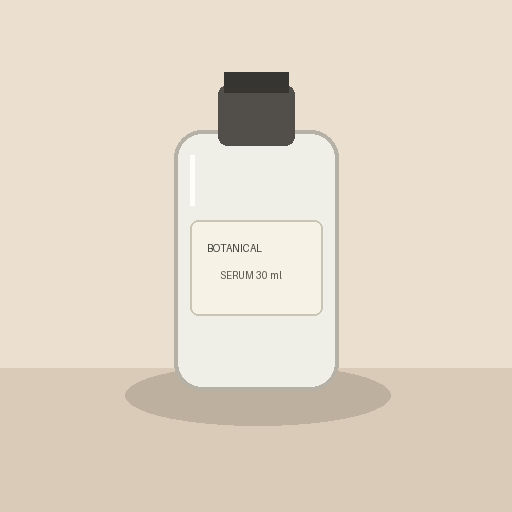

Saved retail_serum_input.png


In [11]:
input_image = make_retail_fixture(IMAGE_SIZE)
input_image.save("retail_serum_input.png")
display(input_image)
print("Saved retail_serum_input.png")

In [12]:
EDIT_PROMPT = ("Edit this product photo for a premium skincare campaign. Change only the serum bottle label to a tasteful deep botanical green. Preserve the bottle shape, cap, camera angle, background, lighting, and composition. Do not add extra products.")
print("Editing instruction:", EDIT_PROMPT)

Editing instruction: Edit this product photo for a premium skincare campaign. Change only the serum bottle label to a tasteful deep botanical green. Preserve the bottle shape, cap, camera angle, background, lighting, and composition. Do not add extra products.


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

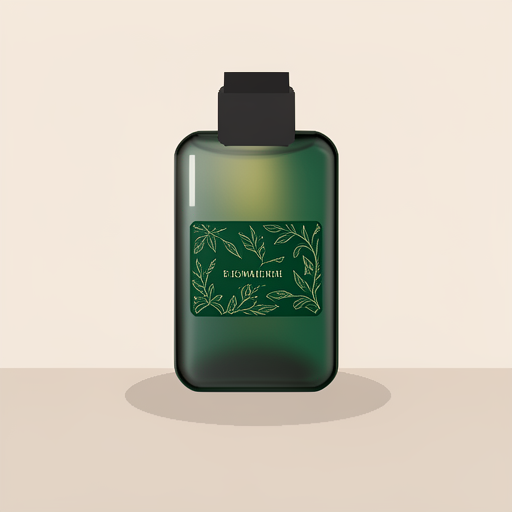

FLUX.2 Klein elapsed: 15.9s; peak allocated GPU memory: 8.10 GiB
Cleared Model A from memory.


In [13]:
FLUX2_ID = "black-forest-labs/FLUX.2-klein-4B"
flux2_pipe = None
flux2_image = None
flux2_seconds = None
flux2_peak_gib = None

try:
    torch.cuda.reset_peak_memory_stats()

    flux2_pipe = Flux2KleinPipeline.from_pretrained(
        FLUX2_ID,
        torch_dtype=torch.float16,
    )

    flux2_pipe.enable_model_cpu_offload()

    gen = torch.Generator(device="cuda").manual_seed(SEED)
    t0 = time.perf_counter()

    with torch.inference_mode():

        flux2_image = flux2_pipe(
            image=input_image,
            prompt=EDIT_PROMPT,
            height=IMAGE_SIZE,
            width=IMAGE_SIZE,
            guidance_scale=1.0,
            num_inference_steps=FLUX2_STEPS,
            generator=gen,
        ).images[0]

    torch.cuda.synchronize()
    flux2_seconds = time.perf_counter() - t0
    flux2_peak_gib = torch.cuda.max_memory_allocated() / 1024**3
    flux2_image.save("flux2_klein_edit.png")
    display(flux2_image)

    print(f"FLUX.2 Klein elapsed: {flux2_seconds:.1f}s; peak allocated GPU memory: {flux2_peak_gib:.2f} GiB")
except Exception as e:
    print("FLUX.2 Klein failed in this runtime:", repr(e))
    print("Record this failure as a feasibility result; do not report a successful image.")
finally:
    if flux2_pipe is not None:
        del flux2_pipe
    gc.collect()
    torch.cuda.empty_cache()

    print("Cleared Model A from memory.")

In [14]:
flux2_review = {
    "edit_instruction_success_1_to_5": 5,
    "bottle_shape_preservation_1_to_5": 5,
    "composition_preservation_1_to_5": 5,
    "visual_quality_1_to_5": 3,
    "label_text_legible": True,  # True / False / "uncertain"
    "notes": ""
}

print(json.dumps(flux2_review, indent=2))

{
  "edit_instruction_success_1_to_5": 5,
  "bottle_shape_preservation_1_to_5": 5,
  "composition_preservation_1_to_5": 5,
  "visual_quality_1_to_5": 3,
  "label_text_legible": true,
  "notes": ""
}


In [ ]:
!pip install -q --upgrade "bitsandbytes==0.48.1" "peft==0.17.1" "protobuf==5.29.5" "sentencepiece==0.2.1" transformers "diffusers==0.35.1" huggingface-hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.9/319.9 kB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 80.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 115.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 58.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
grpc-google-iam-v1 0.14.5 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.5 which is incompatible.
google-cloud-monitoring 2.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.5 which is incompatible.
proto-p

In [ ]:
%pip install --upgrade --no-cache-dir \
    "diffusers[torch]" \
    "transformers" \
    "peft" \
    "accelerate"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 383.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 355.4 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 2.2.0
    Uninstalling huggingface_hub-2.2.0:
      Successfully uninstalled huggingface_hub-2.2.0
  Attempting uninstall: diffusers
    Found existing installation: diffusers 0.35.1
    Uninstalling diffusers-0.35.1:
      Successfully uninstalled diffusers-0.35.1
  Attempting uninstall: peft
    Found existing installation: peft 0.17.1
    Uninstalling peft-0.17.1:
      Successfully uninstalled peft-0.17.1


In [15]:
import gc, time, torch
import logging
from diffusers import FluxKontextPipeline, FluxTransformer2DModel
from diffusers.pipelines.flux.pipeline_flux_kontext import PREFERRED_KONTEXT_RESOLUTIONS
from transformers import T5EncoderModel

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

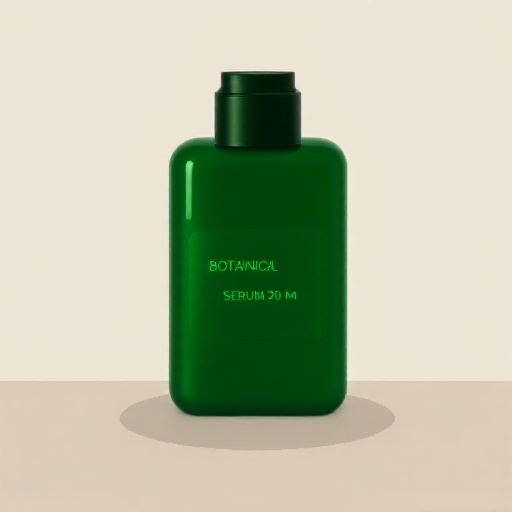

FLUX.1 Kontext NF4 elapsed (including decode): 2.6s; peak allocated GPU memory: 6.54 GiB
Cleared Model B temporary objects.


In [16]:
KONTEXT_ID = "aniketppanchal/flux.1-kontext-dev-nf4-pkg"
kontext_image = None
kontext_seconds = None
kontext_peak_gib = None

try:
    torch.cuda.reset_peak_memory_stats()
    major, _ = torch.cuda.get_device_capability()
    dtype = torch.bfloat16 if major >= 8 else torch.float16
    prompt = EDIT_PROMPT

    # Stage A: encode the prompt; then release the T5 encoder.
    text_encoder_2 = T5EncoderModel.from_pretrained(
        KONTEXT_ID, subfolder="text_encoder_2", torch_dtype=dtype, device_map="cuda"
    )
    pipe = FluxKontextPipeline.from_pretrained(
        KONTEXT_ID, text_encoder_2=text_encoder_2, transformer=None, vae=None,
        torch_dtype=dtype, device_map="cuda"
    )
    with torch.no_grad():
        prompt_embeds, pooled_prompt_embeds, _ = pipe.encode_prompt(
            prompt=prompt, max_sequence_length=256
        )
    del text_encoder_2, pipe
    gc.collect(); torch.cuda.empty_cache()

    # Stage B: encode input image to VAE latents.
    pipe = FluxKontextPipeline.from_pretrained(
        KONTEXT_ID, text_encoder=None, text_encoder_2=None, tokenizer=None,
        tokenizer_2=None, transformer=None, torch_dtype=dtype, device_map="cuda"
    )
    image_h, image_w = pipe.image_processor.get_default_height_width(input_image)
    aspect_ratio = image_w / image_h
    _, preferred_w, preferred_h = min(
        (abs(aspect_ratio - w / h), w, h) for w, h in PREFERRED_KONTEXT_RESOLUTIONS
    )
    multiple_of = pipe.vae_scale_factor * 2
    new_w = max(multiple_of, preferred_w // multiple_of * multiple_of)
    new_h = max(multiple_of, preferred_h // multiple_of * multiple_of)
    # Keep the evaluation footprint at or below 512x512 where possible.
    scale = min(1.0, IMAGE_SIZE / max(new_w, new_h))
    new_w = max(multiple_of, int(new_w * scale) // multiple_of * multiple_of)
    new_h = max(multiple_of, int(new_h * scale) // multiple_of * multiple_of)
    processed = pipe.image_processor.resize(input_image.copy(), new_h, new_w)
    processed = pipe.image_processor.preprocess(processed, new_h, new_w)
    processed = processed.to(device=pipe.device, dtype=pipe.vae.dtype)
    with torch.no_grad():
        image_latents = pipe._encode_vae_image(processed, generator=None)
    del processed, pipe
    gc.collect(); torch.cuda.empty_cache()

    # Stage C: run the NF4 transformer with text/image conditioning.
    transformer = FluxTransformer2DModel.from_pretrained(
        KONTEXT_ID, subfolder="transformer", torch_dtype=dtype, device_map="cuda"
    )
    pipe = FluxKontextPipeline.from_pretrained(
        KONTEXT_ID, text_encoder=None, text_encoder_2=None, tokenizer=None,
        tokenizer_2=None, transformer=transformer, vae=None,
        torch_dtype=dtype, device_map="cuda"
    )
    t0 = time.perf_counter()
    with torch.no_grad():
        packed_latents = pipe(
            image=image_latents,
            height=new_h,
            width=new_w,
            num_inference_steps=KONTEXT_STEPS,
            guidance_scale=3.5,
            prompt_embeds=prompt_embeds,
            pooled_prompt_embeds=pooled_prompt_embeds,
            output_type="latent",
            max_sequence_length=256,
            max_area=new_h * new_w,
        ).images
    torch.cuda.synchronize()
    generation_elapsed = time.perf_counter() - t0
    del image_latents, transformer, pipe
    gc.collect(); torch.cuda.empty_cache()

    # Stage D: decode generated latents to an image.
    pipe = FluxKontextPipeline.from_pretrained(
        KONTEXT_ID, text_encoder=None, text_encoder_2=None, tokenizer=None,
        tokenizer_2=None, transformer=None, torch_dtype=dtype, device_map="cuda"
    )
    unpacked = (pipe._unpack_latents(
        packed_latents, height=new_h, width=new_w, vae_scale_factor=pipe.vae_scale_factor
    ) / pipe.vae.config.scaling_factor + pipe.vae.config.shift_factor).to(
        device=pipe.device, dtype=pipe.vae.dtype
    )
    with torch.no_grad():
        decoded = pipe.vae.decode(unpacked, return_dict=False)[0]
    kontext_image = pipe.image_processor.postprocess(decoded)[0]
    kontext_seconds = time.perf_counter() - t0
    kontext_peak_gib = torch.cuda.max_memory_allocated() / 1024**3
    kontext_image.save("flux1_kontext_nf4_edit.png")
    display(kontext_image)
    print(f"FLUX.1 Kontext NF4 elapsed (including decode): {kontext_seconds:.1f}s; peak allocated GPU memory: {kontext_peak_gib:.2f} GiB")
except Exception as e:
    print("FLUX.1 Kontext NF4 failed in this runtime:", repr(e))
    print("Record the failure and traceback as a feasibility result; do not report a successful image.")
finally:
    for name in ["pipe", "transformer", "prompt_embeds", "pooled_prompt_embeds", "image_latents", "packed_latents", "unpacked", "decoded"]:
        if name in globals():
            try: del globals()[name]
            except Exception: pass
    gc.collect()
    torch.cuda.empty_cache()
    print("Cleared Model B temporary objects.")

In [17]:
kontext_review = {
    "edit_instruction_success_1_to_5": 5,
    "bottle_shape_preservation_1_to_5": 5,
    "composition_preservation_1_to_5": 4,
    "visual_quality_1_to_5": 5,
    "label_text_legible": True,  # True / False / "uncertain"
    "notes": ""
}

print(json.dumps(kontext_review, indent=2))

{
  "edit_instruction_success_1_to_5": 5,
  "bottle_shape_preservation_1_to_5": 5,
  "composition_preservation_1_to_5": 4,
  "visual_quality_1_to_5": 5,
  "label_text_legible": true,
  "notes": ""
}


In [18]:
results = pd.DataFrame([
    {"Model": "FLUX.2 Klein 4B", "Checkpoint": FLUX2_ID,
     "Steps": FLUX2_STEPS, "Runtime seconds": flux2_seconds,
     "Peak allocated VRAM GiB": flux2_peak_gib,
     "Edit success 1-5": flux2_review["edit_instruction_success_1_to_5"],
     "Shape preservation 1-5": flux2_review["bottle_shape_preservation_1_to_5"],
     "Composition preservation 1-5": flux2_review["composition_preservation_1_to_5"],
     "Visual quality 1-5": flux2_review["visual_quality_1_to_5"],
     "Notes": flux2_review["notes"]},
    {"Model": "FLUX.1 Kontext Dev NF4", "Checkpoint": KONTEXT_ID,
     "Steps": KONTEXT_STEPS, "Runtime seconds": kontext_seconds,
     "Peak allocated VRAM GiB": kontext_peak_gib,
     "Edit success 1-5": kontext_review["edit_instruction_success_1_to_5"],
     "Shape preservation 1-5": kontext_review["bottle_shape_preservation_1_to_5"],
     "Composition preservation 1-5": kontext_review["composition_preservation_1_to_5"],
     "Visual quality 1-5": kontext_review["visual_quality_1_to_5"],
     "Notes": kontext_review["notes"]},
])
display(results)
results.to_csv("week2_model_comparison.csv", index=False)

evidence = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "gpu_name": torch.cuda.get_device_name(0),
    "gpu_total_vram_gib": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "image_size": IMAGE_SIZE,
    "seed": SEED,
    "input_image": "retail_serum_input.png",
    "edit_prompt": EDIT_PROMPT,
    "models": [
        {"name": "FLUX.2 Klein 4B", "id": FLUX2_ID, "steps": FLUX2_STEPS,
         "runtime_seconds": flux2_seconds, "peak_allocated_vram_gib": flux2_peak_gib,
         "review": flux2_review, "output_file": "flux2_klein_edit.png" if flux2_image is not None else None},
        {"name": "FLUX.1 Kontext Dev NF4", "id": KONTEXT_ID, "steps": KONTEXT_STEPS,
         "runtime_seconds": kontext_seconds, "peak_allocated_vram_gib": kontext_peak_gib,
         "review": kontext_review, "output_file": "flux1_kontext_nf4_edit.png" if kontext_image is not None else None}
    ]
}

with open("week2_evidence.json", "w") as f:
    json.dump(evidence, f, indent=2, default=str)

print("Saved week2_model_comparison.csv and week2_evidence.json")

,Model,Checkpoint,Steps,Runtime seconds,Peak allocated VRAM GiB,Edit success 1-5,Shape preservation 1-5,Composition preservation 1-5,Visual quality 1-5,Notes
0,FLUX.2 Klein 4B,black-forest-labs/FLUX.2-klein-4B,4,15.941662,8.099891,5,5,5,3,
1,FLUX.1 Kontext Dev NF4,aniketppanchal/flux.1-kontext-dev-nf4-pkg,8,2.565414,6.536852,5,5,4,5,


Saved week2_model_comparison.csv and week2_evidence.json
